In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
medical_dirty = pd.read_csv("realworld_medical_dirty.csv")

In [3]:
medical_clean = medical_dirty.copy()

In [4]:
medical_clean.head(5)

,Patient_ID,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes
0,P1000,55.0,FEMALE,120.0,NaN,35.4,Yes,Heart Disease,2023-12-27,NaN
1,P1001,65.0,Male,150.0,180.0,27.8,NaN,NaN,2023-01-01,NaN
2,P1002,45.0,Male,120.0,220.0,22.5,No,NaN,2023-12-14,NaN
3,P1003,65.0,Male,NaN,180.0,35.4,No,NaN,2023-07-09,NaN
4,P1004,65.0,Male,120.0,300.0,40.1,NaN,NaN,2023-07-10,Follow-up required


**Data Cleaning**

In [5]:
#1. Remove Patient_ID as a column, PII

In [6]:
medical_clean = medical_clean.drop(columns="Patient_ID")

In [7]:
#2 Change Data Type for Admission Data to date time

In [8]:
medical_clean["Admission_Date"] = pd.to_datetime(medical_clean["Admission_Date"])

In [9]:
medical_clean["Month Year"]  = (
    medical_clean["Admission_Date"].dt.month_name() + " " + medical_clean["Admission_Date"].dt.year.astype(str)
)

In [10]:
medical_clean["Year"] = medical_clean["Year"] = medical_clean["Admission_Date"].dt.year.astype(str)

In [11]:
medical_clean

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year
0,55.0,FEMALE,120.0,NaN,35.4,Yes,Heart Disease,2023-12-27,NaN,December 2023,2023
1,65.0,Male,150.0,180.0,27.8,NaN,NaN,2023-01-01,NaN,January 2023,2023
2,45.0,Male,120.0,220.0,22.5,No,NaN,2023-12-14,NaN,December 2023,2023
3,65.0,Male,NaN,180.0,35.4,No,NaN,2023-07-09,NaN,July 2023,2023
4,65.0,Male,120.0,300.0,40.1,NaN,NaN,2023-07-10,Follow-up required,July 2023,2023
...,...,...,...,...,...,...,...,...,...,...,...
95,55.0,MALE,150.0,200.0,35.4,Yes,NaN,2023-07-16,Follow-up required,July 2023,2023
96,55.0,male,NaN,220.0,27.8,Y,NaN,2023-12-17,Follow-up required,December 2023,2023
97,65.0,Female,150.0,200.0,27.8,N,NaN,2023-05-13,Checkup due,May 2023,2023
98,25.0,MALE,NaN,180.0,40.1,Yes,Diabetes,2023-12-24,Follow-up required,December 2023,2023


In [12]:
#3 fill in null values for Notes and Diagnosis and smoker 

In [13]:
medical_clean["Notes"] = medical_clean["Notes"].fillna("No Follow Up Notes")

In [14]:
medical_clean["Diagnosis"] = medical_clean["Diagnosis"].fillna("No Diagnosis")

In [15]:
medical_clean["Smoker"] = medical_clean["Smoker"].fillna("Not Sure")

In [16]:
medical_clean["Smoker"] = medical_clean["Smoker"].replace({
    "Y": "Yes",
    "N": "No"
})

In [17]:
#4 Clean up Gender Column

In [18]:
medical_clean["Gender"] = medical_clean["Gender"].fillna("Unknown")

In [19]:
medical_clean["Gender"].value_counts()

Gender
Male       22
MALE       21
Female     17
FEMALE     15
Unknown    15
male       10
Name: count, dtype: int64

In [20]:
medical_clean["Gender"] = medical_clean["Gender"].replace({
    "MALE": "Male",
    "male": "Male",
    "FEMALE": "Female"
})

In [21]:
medical_clean["Gender"] = medical_clean["Gender"].str.strip().str.title()

In [22]:
medical_clean["Gender"].value_counts()

Gender
Male       53
Female     32
Unknown    15
Name: count, dtype: int64

In [23]:
#4 check if there are nulls in the age, blood pressure, cholestrol and BMI categories, if so handle them apporiately 

In [24]:
cols = ["Age", "Blood_Pressure", "Cholesterol", "BMI"]

In [25]:
null_counts = medical_clean[cols].isnull().sum()
null_pct = (null_counts / len(medical_clean) * 100).round(2)

null_summary = pd.DataFrame({
    'null_count': null_counts,
    'null_pct': null_pct
})

In [26]:
print(null_summary[null_summary['null_count'] > 0])

                null_count  null_pct
Age                     17      17.0
Blood_Pressure          14      14.0
Cholesterol             20      20.0
BMI                     20      20.0


In [27]:
medical_clean.head(5)

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year
0,55.0,Female,120.0,NaN,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023
3,65.0,Male,NaN,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023


In [28]:
from scipy import stats

num_cols = ["Age", "Blood_Pressure", "Cholesterol", "BMI"]
cat_cols = ["Gender", "Smoker", "Diagnosis", "Notes", "Year"]

In [29]:
rows = []
for target in num_cols:
    is_missing = medical_clean[target].isnull()

    # Categorical columns: chi-square test
    for col in cat_cols:
        table = pd.crosstab(medical_clean[col], is_missing)
        chi2, p, dof, expected = stats.chi2_contingency(table)
        rows.append({"missing_col": target, "vs": col, "test": "chi-square",
                     "p_value": round(p, 4), "min_expected": round(expected.min(), 1)})

    # Numeric columns: compare values when target is missing vs present
    for col in num_cols:
        if col == target:
            continue
        missing_grp = medical_clean.loc[is_missing, col].dropna()
        present_grp = medical_clean.loc[~is_missing, col].dropna()
        stat, p = stats.mannwhitneyu(missing_grp, present_grp)
        rows.append({"missing_col": target, "vs": col, "test": "Mann-Whitney",
                     "p_value": round(p, 4), "min_expected": None})

results = pd.DataFrame(rows).sort_values("p_value")
results

,missing_col,vs,test,p_value,min_expected
14,Blood_Pressure,Cholesterol,Mann-Whitney,0.0521,NaN
1,Age,Smoker,chi-square,0.0567,3.4
17,Cholesterol,Smoker,chi-square,0.1213,4.0
22,Cholesterol,Blood_Pressure,Mann-Whitney,0.1347,NaN
29,BMI,Age,Mann-Whitney,0.1355,NaN
31,BMI,Cholesterol,Mann-Whitney,0.1434,NaN
7,Age,BMI,Mann-Whitney,0.1458,NaN
2,Age,Diagnosis,chi-square,0.1602,4.2
8,Blood_Pressure,Gender,chi-square,0.1699,2.1
21,Cholesterol,Age,Mann-Whitney,0.1749,NaN


In [30]:
medical_clean[num_cols].isnull().corr()

,Age,Blood_Pressure,Cholesterol,BMI
Age,1.000000,-0.105877,-9.317610e-02,-9.317610e-02
Blood_Pressure,-0.105877,1.000000,-5.763904e-02,1.585074e-01
Cholesterol,-0.093176,-0.057639,1.000000e+00,1.821460e-17
BMI,-0.093176,0.158507,1.821460e-17,1.000000e+00


In [31]:
pd.crosstab(medical_clean["Smoker"], medical_clean["Age"].isnull(), normalize="index")

Age,False,True
Smoker,,
No,0.875,0.125
Not Sure,0.950,0.050
Yes,0.725,0.275


In [32]:
#5 apply median imputation to replace the null values for the numeric values 

In [33]:
for col in num_cols:
    medical_clean[f"{col}_was_missing"] = medical_clean[col].isnull()
    medical_clean[col] = medical_clean[col].fillna(medical_clean[col].median())

In [34]:
null_counts = medical_clean[cols].isnull().sum()
null_pct = (null_counts / len(medical_clean) * 100).round(2)

null_summary = pd.DataFrame({
    'null_count': null_counts,
    'null_pct': null_pct
})

In [35]:
print(null_summary[null_summary['null_count'] > 0])

Empty DataFrame
Columns: [null_count, null_pct]
Index: []


In [36]:
medical_clean.dtypes

Age                                  float64
Gender                                   str
Blood_Pressure                       float64
Cholesterol                          float64
BMI                                  float64
Smoker                                   str
Diagnosis                                str
Admission_Date                datetime64[us]
Notes                                    str
Month Year                               str
Year                                     str
Age_was_missing                         bool
Blood_Pressure_was_missing              bool
Cholesterol_was_missing                 bool
BMI_was_missing                         bool
dtype: object

In [37]:
medical_clean.head(5)

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year,Age_was_missing,Blood_Pressure_was_missing,Cholesterol_was_missing,BMI_was_missing
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023,False,False,True,False
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023,False,False,False,False
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023,False,False,False,False
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023,False,True,False,False
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023,False,False,False,False


**Convert Month Year and Year to date formats and set to apporaite values**

In [38]:
medical_clean["Month Year"] = pd.to_datetime(medical_clean["Month Year"])
medical_clean["Month Year"] = medical_clean["Month Year"].dt.strftime("%B %Y") 

C:\Users\alexh\AppData\Local\Temp\ipykernel_15252\763906726.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  medical_clean["Month Year"] = pd.to_datetime(medical_clean["Month Year"])


In [39]:
medical_clean["Year"] = pd.to_datetime(medical_clean["Year"])
medical_clean["Year"] = medical_clean["Year"].dt.year

In [40]:
medical_clean.head(5)

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year,Age_was_missing,Blood_Pressure_was_missing,Cholesterol_was_missing,BMI_was_missing
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023,False,False,True,False
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023,False,False,False,False
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023,False,False,False,False
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023,False,True,False,False
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023,False,False,False,False


**Create two new Column Gender_Female and Gender_Male as boolean values**

In [41]:
gender_dummies = pd.get_dummies(medical_clean["Gender"], prefix="Gender", dtype=bool)
medical_clean = medical_clean.join(gender_dummies)
medical_clean

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,Year,Age_was_missing,Blood_Pressure_was_missing,Cholesterol_was_missing,BMI_was_missing,Gender_Female,Gender_Male,Gender_Unknown
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,2023,False,False,True,False,True,False,False
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,2023,False,False,False,False,False,True,False
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,2023,False,False,False,False,False,True,False
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,2023,False,True,False,False,False,True,False
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,2023,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,55.0,Male,150.0,200.0,35.4,Yes,No Diagnosis,2023-07-16,Follow-up required,July 2023,2023,False,False,False,False,False,True,False
96,55.0,Male,140.0,220.0,27.8,Yes,No Diagnosis,2023-12-17,Follow-up required,December 2023,2023,False,True,False,False,False,True,False
97,65.0,Female,150.0,200.0,27.8,No,No Diagnosis,2023-05-13,Checkup due,May 2023,2023,False,False,False,False,True,False,False
98,25.0,Male,140.0,180.0,40.1,Yes,Diabetes,2023-12-24,Follow-up required,December 2023,2023,False,True,False,False,False,True,False


In [42]:
medical_clean.dtypes

Age                                  float64
Gender                                   str
Blood_Pressure                       float64
Cholesterol                          float64
BMI                                  float64
Smoker                                   str
Diagnosis                                str
Admission_Date                datetime64[us]
Notes                                    str
Month Year                               str
Year                                   int32
Age_was_missing                         bool
Blood_Pressure_was_missing              bool
Cholesterol_was_missing                 bool
BMI_was_missing                         bool
Gender_Female                           bool
Gender_Male                             bool
Gender_Unknown                          bool
dtype: object

**Perform More Feature Engineering**

In [43]:
medical_clean["Missing Follow Up Notes"] = np.where(medical_clean["Notes"] == "No Follow Up Notes", True, False).astype(bool)
medical_clean["Smoking Diagnosis is Unclear"] = np.where(medical_clean["Smoker"] == "Not Sure", True, False).astype(bool)
medical_clean["Missing Diagnosis"] = np.where(medical_clean["Diagnosis"] == "No Diagnosis", True, False).astype(bool)

**Perform Feature Engineering, define blood pressure, cholestrol and bmi levels**

In [44]:
def classify_blood_pressure(bp):
    """Systolic BP categories (American Heart Association)."""
    if pd.isna(bp):
        return "Unknown"
    elif bp < 120:
        return "Normal"
    elif bp < 130:
        return "Elevated"
    elif bp < 140:
        return "Hypertension Stage 1"
    elif bp <= 180:
        return "Hypertension Stage 2"
    else:
        return "Hypertensive Crisis"


def classify_cholesterol(chol):
    """Total cholesterol categories in mg/dL (NIH / NCEP)."""
    if pd.isna(chol):
        return "Unknown"
    elif chol < 200:
        return "Desirable"
    elif chol < 240:
        return "Borderline High"
    else:
        return "High"


def classify_bmi(bmi):
    """Adult BMI categories (CDC / WHO)."""
    if pd.isna(bmi):
        return "Unknown"
    elif bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

def classify_age_group(age):
    """Age groups in 10-year bands, with 65+ as its own group."""
    if pd.isna(age):
        return "Unknown"
    elif age < 18:
        return "Under 18"
    elif age < 30:
        return "18-29"
    elif age < 40:
        return "30-39"
    elif age < 50:
        return "40-49"
    elif age < 55:
        return "50-54"
    elif age < 65:
        return "55-64"
    else:
        return "65+"

medical_clean["BP_Category"] = medical_clean["Blood_Pressure"].apply(classify_blood_pressure)
medical_clean["Cholesterol_Category"] = medical_clean["Cholesterol"].apply(classify_cholesterol)
medical_clean["BMI_Category"] = medical_clean["BMI"].apply(classify_bmi)
medical_clean["Age_Group"] = medical_clean["Age"].apply(classify_age_group)
medical_clean["Age_Group"].value_counts().sort_index()

Age_Group
18-29    11
30-39    19
40-49    11
55-64    42
65+      17
Name: count, dtype: int64

**Check for outliers in numeric columns**

In [45]:
def iqr_outliers(df, col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return df[(df[col] < lower) | (df[col] > upper)], lower, upper

for col in num_cols:
    out, lo, hi = iqr_outliers(medical_clean, col)
    print(f"{col}: {len(out)} outliers (bounds {lo:.1f} - {hi:.1f}")

Age: 0 outliers (bounds 5.0 - 85.0
Blood_Pressure: 0 outliers (bounds 100.0 - 180.0
Cholesterol: 0 outliers (bounds 125.0 - 325.0
BMI: 0 outliers (bounds 16.4 - 46.8


**Exploratory Data Analysis**

1. return distribution of data

In [46]:
num_cols = ["Age", "Blood_Pressure", "Cholesterol", "BMI"]

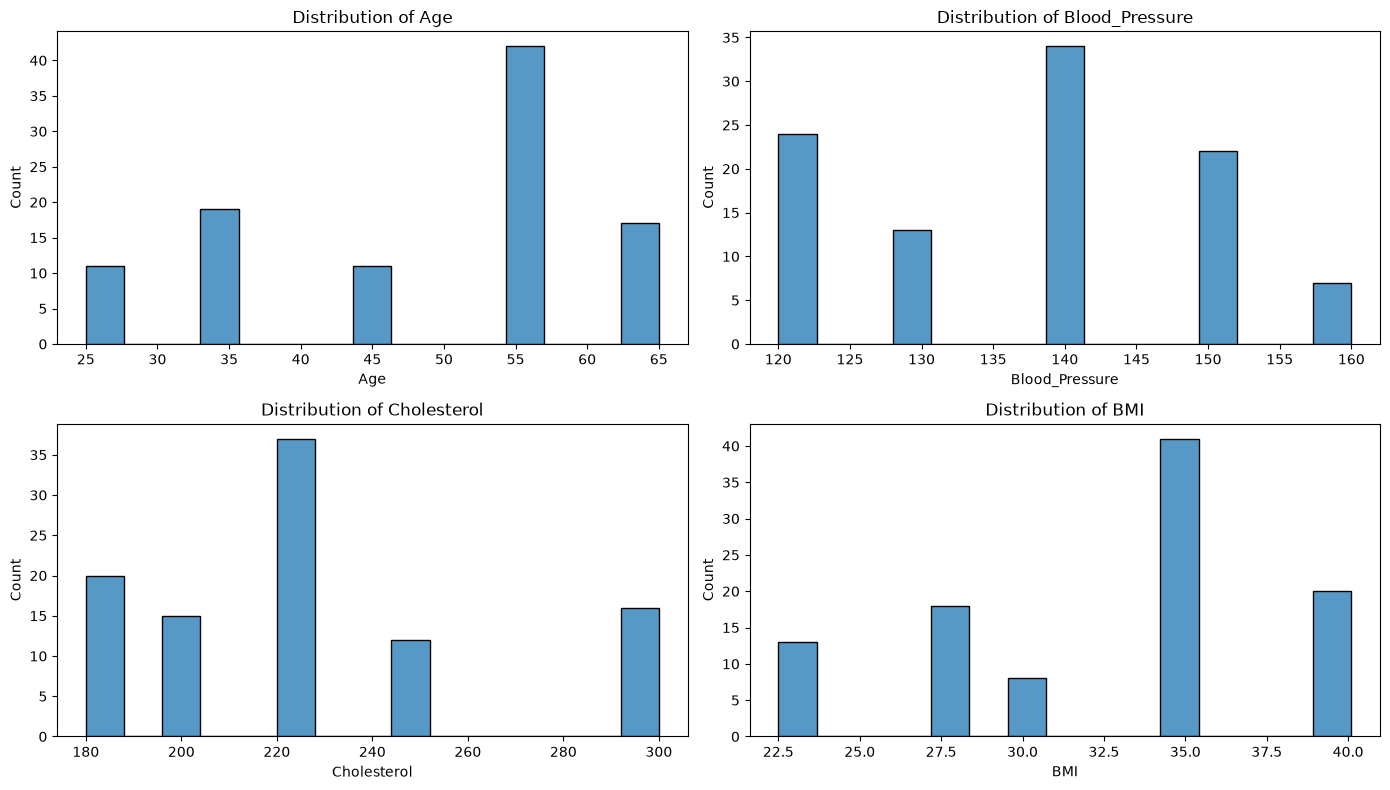

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=medical_clean, x=col, bins=15, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

2. check for correlationns between numeric columns
- none of the numeric variables are strongly correlated with another

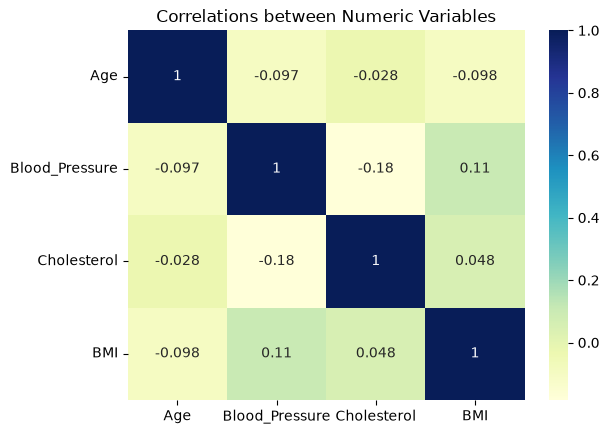

In [48]:
num_cols_corr = medical_clean[["Age", "Blood_Pressure", "Cholesterol", "BMI"]].corr(numeric_only=True)
sns.heatmap(num_cols_corr, cmap="YlGnBu", annot=True)
plt.title("Correlations between Numeric Variables")
plt.show()

In [49]:
medical_clean.dtypes

Age                                    float64
Gender                                     str
Blood_Pressure                         float64
Cholesterol                            float64
BMI                                    float64
Smoker                                     str
Diagnosis                                  str
Admission_Date                  datetime64[us]
Notes                                      str
Month Year                                 str
Year                                     int32
Age_was_missing                           bool
Blood_Pressure_was_missing                bool
Cholesterol_was_missing                   bool
BMI_was_missing                           bool
Gender_Female                             bool
Gender_Male                               bool
Gender_Unknown                            bool
Missing Follow Up Notes                   bool
Smoking Diagnosis is Unclear              bool
Missing Diagnosis                         bool
BP_Category  

In [50]:
pt = medical_clean.pivot_table(index="Diagnosis", 
                          columns=["Smoker"],
                          values="Notes",
                          aggfunc="count")

pt["Total"] = pt.sum(axis=1)

pt["Percent_Smoking"] = (
    pt["Yes"] / pt["Total"] * 100).round(2)

pt

Smoker,No,Not Sure,Yes,Total,Percent_Smoking
Diagnosis,,,,,
Diabetes,11,5,11,27,40.74
Heart Disease,10,5,10,25,40.00
No Diagnosis,19,10,19,48,39.58


In [51]:
pt1 = medical_clean.pivot_table(index="Gender",
                               columns=["Smoker"],
                               values="Notes",
                               aggfunc="count",
                               fill_value=0)

pt1["Total"] = pt1.sum(axis=1)

pt1["Percent_Smoking"] = (
    pt1["Yes"] / pt1["Total"] * 100).round(1)

pt1

Smoker,No,Not Sure,Yes,Total,Percent_Smoking
Gender,,,,,
Female,13,6,13,32,40.6
Male,20,14,19,53,35.8
Unknown,7,0,8,15,53.3


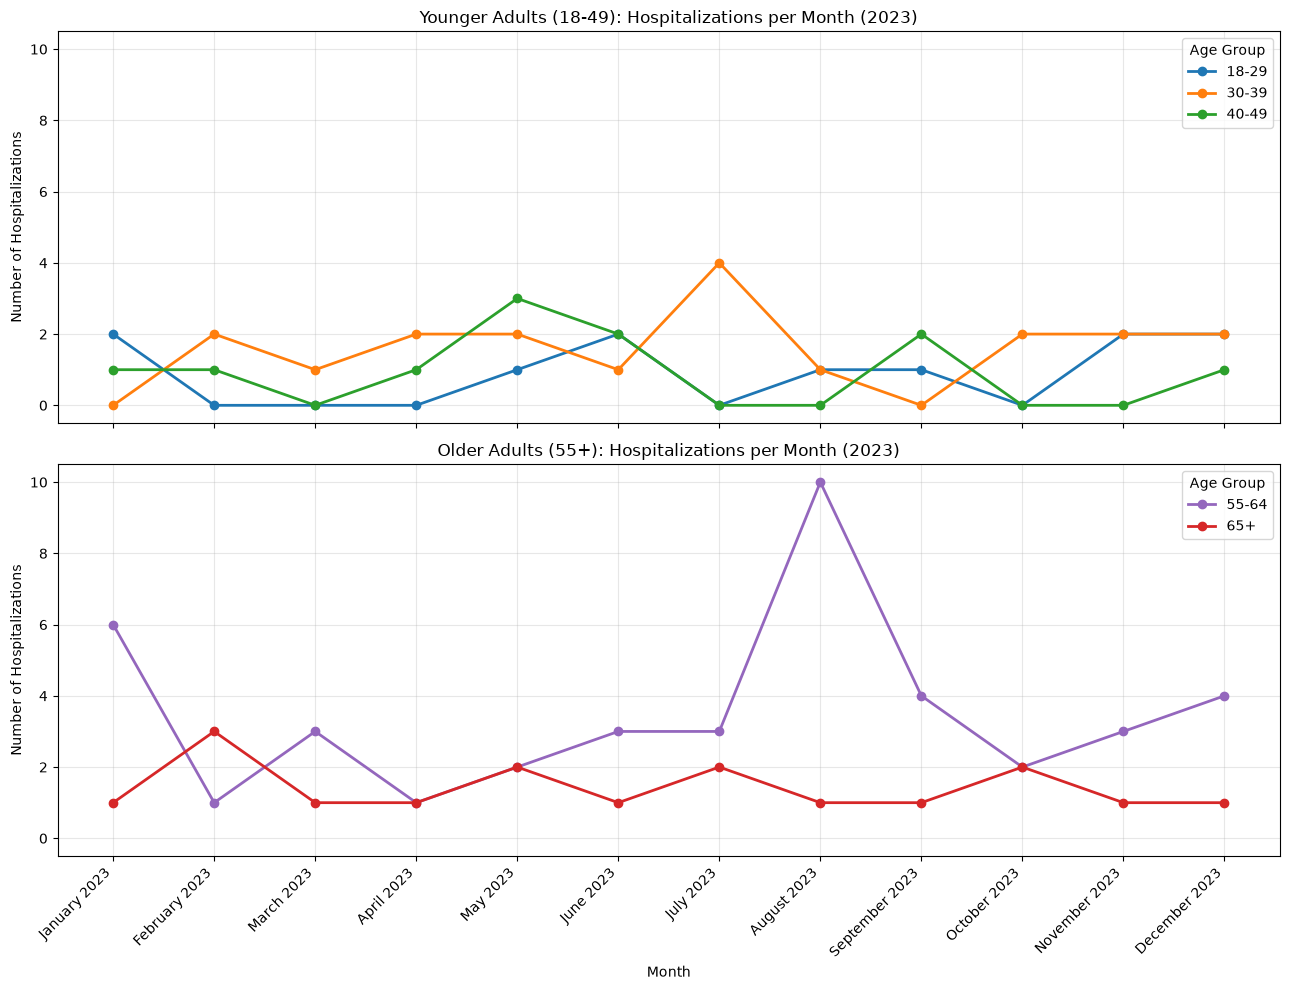

In [52]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

#showcases hospitalizations by age group by year 
age_month_counts = (
    medical_clean
    .groupby([medical_clean["Admission_Date"].dt.to_period("M"), "Age_Group"])
    .size()
    .unstack(fill_value=0)
)

age_month_counts.index = age_month_counts.index.strftime("%B %Y")

#split into two different age groups 
younger_groups = ["18-29", "30-39", "40-49"]
older_groups = ["55-64", "65+"]

# Set the legend to one unique color per group
age_colors = {
    "18-29": "#1f77b4",   # blue
    "30-39": "#ff7f0e",   # orange
    "40-49": "#2ca02c",   # green
    "55-64": "#9467bd",   # purple
    "65+":   "#d62728",   # red
}

# Two charts stacked vertically, sharing the same axes
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10), sharex=True, sharey=True)

# 2. Then plot onto it, with colors
age_month_counts[younger_groups].plot(
    ax=ax1, marker="o", linewidth=2,
    color=[age_colors[g] for g in younger_groups]
)
ax1.set_title("Younger Adults (18-49): Hospitalizations per Month (2023)")
ax1.set_ylabel("Number of Hospitalizations")
ax1.legend(title="Age Group")
ax1.grid(alpha=0.3)

age_month_counts[older_groups].plot(
    ax=ax2, marker="o", linewidth=2,
    color=[age_colors[g] for g in older_groups]
)
ax2.set_title("Older Adults (55+): Hospitalizations per Month (2023)")
ax2.set_ylabel("Number of Hospitalizations")
ax2.set_xlabel("Month")
ax2.legend(title="Age Group")
ax2.grid(alpha=0.3)

ax2.set_xticks(range(len(age_month_counts)))
ax2.set_xticklabels(age_month_counts.index, rotation=45, ha="right")
ax2.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

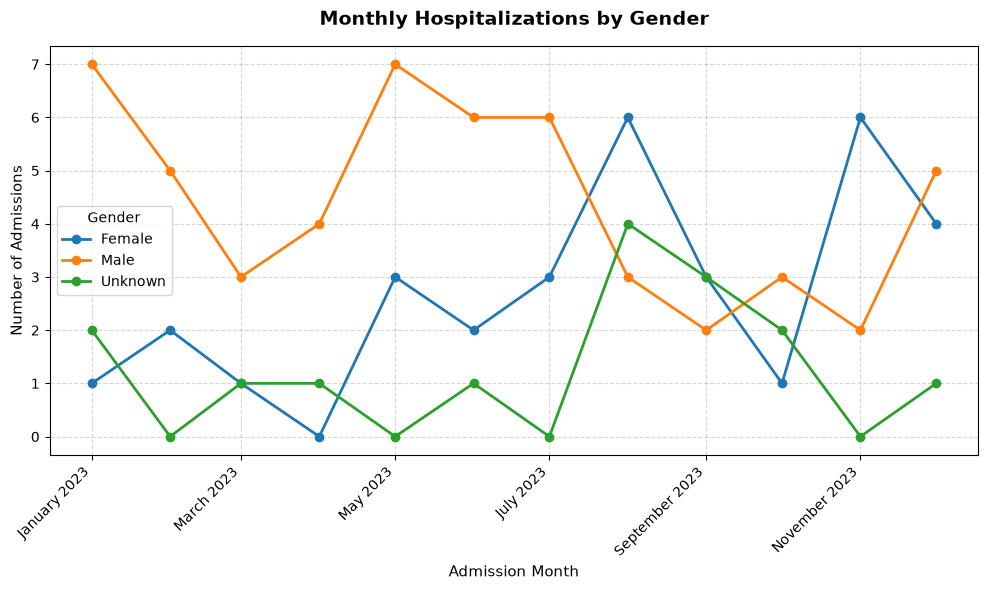

In [53]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Your existing aggregation code
gender_counts = (
    medical_clean.groupby(
        [medical_clean["Admission_Date"].dt.to_period("M"), "Gender"]
    )
    .size()
    .unstack(fill_value=0)
)

# Convert PeriodIndex to DatetimeIndex for smooth plotting
gender_counts.index = gender_counts.index.to_timestamp()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot a line for each gender column
for gender in gender_counts.columns:
  ax.plot(
      gender_counts.index,
      gender_counts[gender],
      marker="o",
      linewidth=2,
      label=gender,
  )

# Format the title and axis labels
ax.set_title(
    "Monthly Hospitalizations by Gender", fontsize=14, fontweight="bold", pad=15
)
ax.set_xlabel("Admission Month", fontsize=11)
ax.set_ylabel("Number of Admissions", fontsize=11)

# Format the y-axis with commas
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Format the x-axis dates as "January 2023" and right-align rotated labels
ax.xaxis.set_major_formatter(mdates.DateFormatter("%B %Y"))
plt.xticks(rotation=45, ha="right")

# Add a subtle grid and legend
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Gender", frameon=True)

# Prevent label cutoff and display
plt.tight_layout()
plt.show()

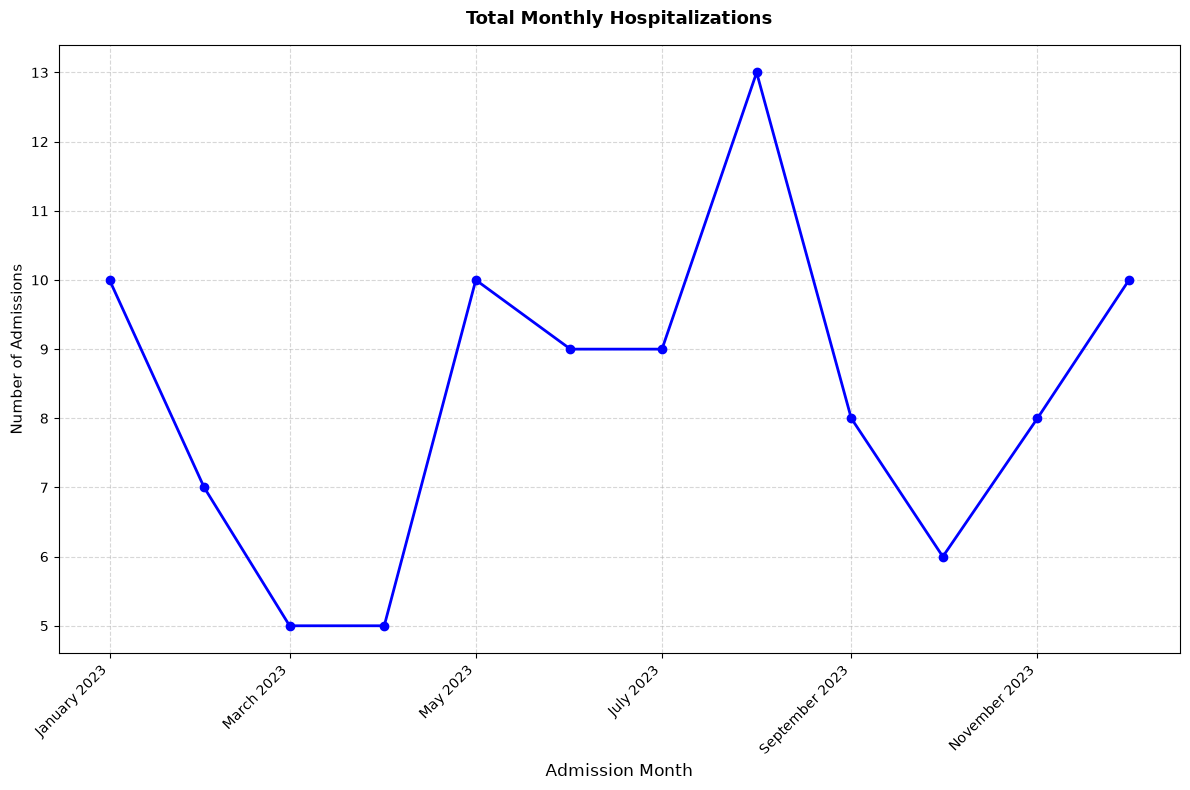

In [54]:
monthly_counts = medical_clean.groupby(
    medical_clean["Admission_Date"].dt.to_period("M")
).size()

monthly_counts.index = monthly_counts.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(monthly_counts.index,
       monthly_counts.values,
       marker="o",
       linewidth=2,
       color="blue",
       )

ax.set_title("Total Monthly Hospitalizations", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Admission Month", fontsize=12)
ax.set_ylabel("Number of Admissions", fontsize=11)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%B %Y"))
plt.xticks(rotation=45, ha="right")

ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [55]:
diagnosis_obtained = medical_clean[medical_clean["Diagnosis"] != "No Diagnosis"]
diagnosis_obtained

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,...,Gender_Female,Gender_Male,Gender_Unknown,Missing Follow Up Notes,Smoking Diagnosis is Unclear,Missing Diagnosis,BP_Category,Cholesterol_Category,BMI_Category,Age_Group
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,...,True,False,False,True,False,False,Elevated,Borderline High,Obese,55-64
5,35.0,Female,130.0,200.0,35.4,No,Heart Disease,2023-11-08,Follow-up required,November 2023,...,True,False,False,False,False,False,Hypertension Stage 1,Borderline High,Obese,30-39
8,45.0,Male,140.0,200.0,35.4,No,Diabetes,2023-02-27,No Follow Up Notes,February 2023,...,False,True,False,True,False,False,Hypertension Stage 2,Borderline High,Obese,40-49
9,65.0,Male,130.0,220.0,35.4,No,Diabetes,2023-02-13,Checkup due,February 2023,...,False,True,False,False,False,False,Hypertension Stage 1,Borderline High,Obese,65+
12,55.0,Male,160.0,180.0,27.8,Yes,Diabetes,2023-06-22,No Follow Up Notes,June 2023,...,False,True,False,True,False,False,Hypertension Stage 2,Desirable,Overweight,55-64
15,55.0,Male,140.0,250.0,30.0,No,Diabetes,2023-05-29,Checkup due,May 2023,...,False,True,False,False,False,False,Hypertension Stage 2,High,Obese,55-64
17,55.0,Female,130.0,220.0,27.8,Yes,Diabetes,2023-08-01,Follow-up required,August 2023,...,True,False,False,False,False,False,Hypertension Stage 1,Borderline High,Overweight,55-64
20,65.0,Male,140.0,220.0,35.4,No,Diabetes,2023-08-17,Follow-up required,August 2023,...,False,True,False,False,False,False,Hypertension Stage 2,Borderline High,Obese,65+
22,55.0,Unknown,120.0,180.0,27.8,No,Diabetes,2023-08-15,No Follow Up Notes,August 2023,...,False,False,True,True,False,False,Elevated,Desirable,Overweight,55-64
23,35.0,Female,120.0,250.0,35.4,Yes,Diabetes,2023-05-27,No Follow Up Notes,May 2023,...,True,False,False,True,False,False,Elevated,High,Obese,30-39


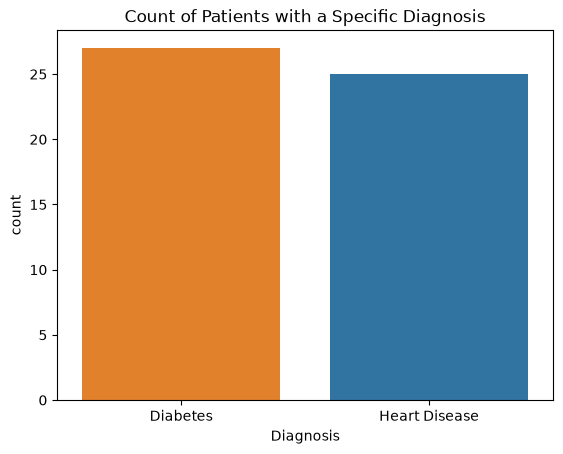

In [56]:
order1 = diagnosis_obtained["Diagnosis"].value_counts().index
sns.countplot(data=diagnosis_obtained, x="Diagnosis", order=order1, hue="Diagnosis")
plt.title("Count of Patients with a Specific Diagnosis")
plt.show()

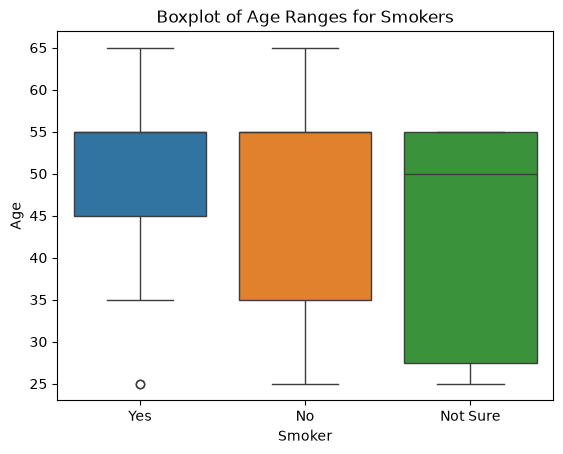

In [57]:
sns.boxplot(data=diagnosis_obtained, x="Smoker", y="Age", hue="Smoker")
plt.title("Boxplot of Age Ranges for Smokers")
plt.show()

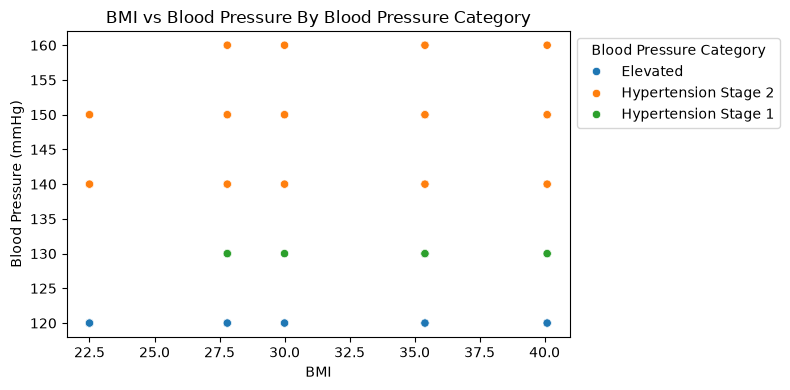

In [58]:
plt.subplots(figsize=(8, 4))
ax = sns.scatterplot(data=medical_clean, x="BMI", y="Blood_Pressure", hue="BP_Category")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title="Blood Pressure Category")
ax.set_ylabel("Blood Pressure (mmHg)")
ax.set_title("BMI vs Blood Pressure By Blood Pressure Category")
plt.tight_layout()
plt.show()

**Cluster 1: Blood Pressure and Cholesterol**

In [59]:
cluster1 = medical_clean[["Blood_Pressure", "Cholesterol"]]

In [60]:
X = cluster1.iloc[:, [0, 1]].values

In [61]:
X

array([[120., 220.],
       [150., 180.],
       [120., 220.],
       [140., 180.],
       [120., 300.],
       [130., 200.],
       [150., 220.],
       [150., 200.],
       [140., 200.],
       [130., 220.],
       [140., 220.],
       [120., 300.],
       [160., 180.],
       [120., 250.],
       [120., 180.],
       [140., 250.],
       [120., 180.],
       [130., 220.],
       [130., 300.],
       [150., 250.],
       [140., 220.],
       [160., 180.],
       [120., 180.],
       [120., 250.],
       [140., 220.],
       [140., 220.],
       [130., 220.],
       [160., 220.],
       [150., 220.],
       [130., 220.],
       [140., 220.],
       [150., 220.],
       [140., 300.],
       [140., 220.],
       [120., 220.],
       [140., 220.],
       [160., 220.],
       [150., 200.],
       [130., 300.],
       [140., 220.],
       [140., 180.],
       [140., 250.],
       [120., 180.],
       [120., 300.],
       [150., 250.],
       [140., 300.],
       [140., 220.],
       [160.,

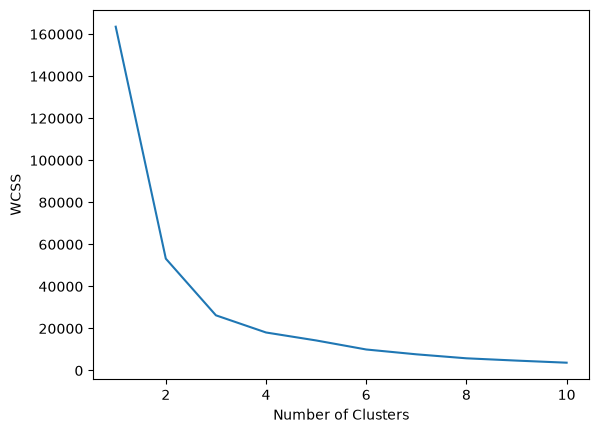

In [62]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [63]:
kmeans = KMeans(n_clusters=6, init="k-means++", random_state=42)
y_kmeans = kmeans.fit_predict(X)

In [64]:
centroids = pd.DataFrame(
    kmeans.cluster_centers_, columns=["Blood Pressure", "Cholesterol"]
)

print(centroids)

   Blood Pressure  Cholesterol
0      149.411765   191.764706
1      131.875000   300.000000
2      145.600000   220.000000
3      137.500000   250.000000
4      123.529412   214.117647
5      131.538462   180.000000


In [65]:
cluster_names = {
    0: "Low BP / Low Chol",
    1: "Normal BP / Normal Chol",
    2: "High BP / Normal Chol",
    3: "Normal BP / High Chol",
    4: "High BP / High Chol",
    5: "Very High BP / High Chol",
}


In [66]:
medical_clean["Cluster"] = y_kmeans
medical_clean["Cluster_Label"] = medical_clean["Cluster"].map(cluster_names)

In [67]:
medical_clean

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,...,Gender_Unknown,Missing Follow Up Notes,Smoking Diagnosis is Unclear,Missing Diagnosis,BP_Category,Cholesterol_Category,BMI_Category,Age_Group,Cluster,Cluster_Label
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,...,False,True,False,False,Elevated,Borderline High,Obese,55-64,4,High BP / High Chol
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,...,False,True,True,True,Hypertension Stage 2,Desirable,Overweight,65+,0,Low BP / Low Chol
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,...,False,True,False,True,Elevated,Borderline High,Normal,40-49,4,High BP / High Chol
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,...,False,True,False,True,Hypertension Stage 2,Desirable,Obese,65+,5,Very High BP / High Chol
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,...,False,False,True,True,Elevated,High,Obese,65+,1,Normal BP / Normal Chol
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,55.0,Male,150.0,200.0,35.4,Yes,No Diagnosis,2023-07-16,Follow-up required,July 2023,...,False,False,False,True,Hypertension Stage 2,Borderline High,Obese,55-64,0,Low BP / Low Chol
96,55.0,Male,140.0,220.0,27.8,Yes,No Diagnosis,2023-12-17,Follow-up required,December 2023,...,False,False,False,True,Hypertension Stage 2,Borderline High,Overweight,55-64,2,High BP / Normal Chol
97,65.0,Female,150.0,200.0,27.8,No,No Diagnosis,2023-05-13,Checkup due,May 2023,...,False,False,False,True,Hypertension Stage 2,Borderline High,Overweight,65+,0,Low BP / Low Chol
98,25.0,Male,140.0,180.0,40.1,Yes,Diabetes,2023-12-24,Follow-up required,December 2023,...,False,False,False,False,Hypertension Stage 2,Desirable,Obese,18-29,5,Very High BP / High Chol


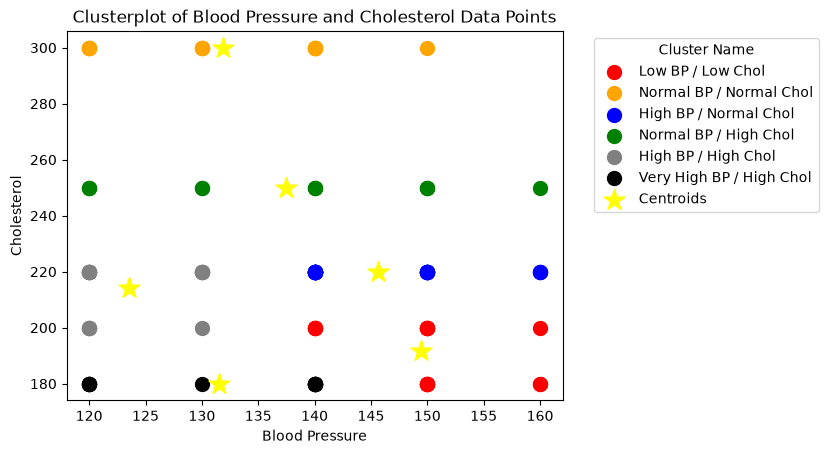

In [68]:
colors = ["red", "orange", "blue", "green", "grey", "black"]

for cluster_id, color in enumerate(colors):
    plt.scatter(
        X[y_kmeans == cluster_id, 0],
        X[y_kmeans == cluster_id, 1],
        s=100,
        c=color,
        label=cluster_names[cluster_id]
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=250,
    c="yellow",
    marker="*",
    label="Centroids",
)

plt.title("Clusterplot of Blood Pressure and Cholesterol Data Points")
plt.xlabel("Blood Pressure")
plt.ylabel("Cholesterol")
plt.legend(title="Cluster Name", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

In [69]:
cluster_summary = (
    medical_clean.groupby(["Cluster", "Cluster_Label"])[
        ["Blood_Pressure", "Cholesterol"]
    ]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

print(cluster_summary)

                                 Blood_Pressure                               \
                                          count    mean    std    min    max   
Cluster Cluster_Label                                                          
0       Low BP / Low Chol                    17  149.41   6.59  140.0  160.0   
1       Normal BP / Normal Chol              16  131.88   9.81  120.0  150.0   
2       High BP / Normal Chol                25  145.60   7.12  140.0  160.0   
3       Normal BP / High Chol                12  137.50  13.57  120.0  160.0   
4       High BP / High Chol                  17  123.53   4.93  120.0  130.0   
5       Very High BP / High Chol             13  131.54   9.87  120.0  140.0   

                                 Cholesterol                               
                                       count    mean    std    min    max  
Cluster Cluster_Label                                                      
0       Low BP / Low Chol                 17  191.7

**Classification Model**
- X: Numeric and Categorical Features
- Y: Did the Person Smoke?

In [70]:
medical_clean

,Age,Gender,Blood_Pressure,Cholesterol,BMI,Smoker,Diagnosis,Admission_Date,Notes,Month Year,...,Gender_Unknown,Missing Follow Up Notes,Smoking Diagnosis is Unclear,Missing Diagnosis,BP_Category,Cholesterol_Category,BMI_Category,Age_Group,Cluster,Cluster_Label
0,55.0,Female,120.0,220.0,35.4,Yes,Heart Disease,2023-12-27,No Follow Up Notes,December 2023,...,False,True,False,False,Elevated,Borderline High,Obese,55-64,4,High BP / High Chol
1,65.0,Male,150.0,180.0,27.8,Not Sure,No Diagnosis,2023-01-01,No Follow Up Notes,January 2023,...,False,True,True,True,Hypertension Stage 2,Desirable,Overweight,65+,0,Low BP / Low Chol
2,45.0,Male,120.0,220.0,22.5,No,No Diagnosis,2023-12-14,No Follow Up Notes,December 2023,...,False,True,False,True,Elevated,Borderline High,Normal,40-49,4,High BP / High Chol
3,65.0,Male,140.0,180.0,35.4,No,No Diagnosis,2023-07-09,No Follow Up Notes,July 2023,...,False,True,False,True,Hypertension Stage 2,Desirable,Obese,65+,5,Very High BP / High Chol
4,65.0,Male,120.0,300.0,40.1,Not Sure,No Diagnosis,2023-07-10,Follow-up required,July 2023,...,False,False,True,True,Elevated,High,Obese,65+,1,Normal BP / Normal Chol
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,55.0,Male,150.0,200.0,35.4,Yes,No Diagnosis,2023-07-16,Follow-up required,July 2023,...,False,False,False,True,Hypertension Stage 2,Borderline High,Obese,55-64,0,Low BP / Low Chol
96,55.0,Male,140.0,220.0,27.8,Yes,No Diagnosis,2023-12-17,Follow-up required,December 2023,...,False,False,False,True,Hypertension Stage 2,Borderline High,Overweight,55-64,2,High BP / Normal Chol
97,65.0,Female,150.0,200.0,27.8,No,No Diagnosis,2023-05-13,Checkup due,May 2023,...,False,False,False,True,Hypertension Stage 2,Borderline High,Overweight,65+,0,Low BP / Low Chol
98,25.0,Male,140.0,180.0,40.1,Yes,Diabetes,2023-12-24,Follow-up required,December 2023,...,False,False,False,False,Hypertension Stage 2,Desirable,Obese,18-29,5,Very High BP / High Chol


In [73]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import classification_report, roc_auc_score 
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from sklearn.metrics import make_scorer, precision_score

In [74]:
smoking_options = medical_clean[medical_clean["Smoker"].isin(["Yes", "No"])].copy()

In [75]:
features = [
    "Age", 	
    "Blood_Pressure", 	
    "Cholesterol",	
    "BMI",
    "Gender_Male",
    "Gender_Female",
]

X = pd.get_dummies(smoking_options[features + ["Diagnosis"]], drop_first=True, dtype=int)
Y = (smoking_options["Smoker"] == "Yes").astype(int)

In [77]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, stratify=Y, random_state=42
)

In [78]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [79]:
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0)
}

In [80]:
models = {
    "Logistic Classification": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Decision Tree Classification": DecisionTreeClassifier(max_depth=6, random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(random_state=42)),
    "Random Forest Classification": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.10, max_depth=5,
                         subsample=0.75, colsample_bytree=0.7,
                         eval_metric="logloss", random_state=42, n_jobs=-1)
}

In [81]:
rows = []
for name, model in models.items():
    r = cross_validate(model, X_train, Y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "roc_auc": r["test_roc_auc"].mean(), 
        "roc_auc_sd": r["test_roc_auc"].std(),
        "accuracy": r["test_accuracy"].mean(),
        "recall_detected": r["test_recall"].mean(),
        "precision_detected": r["test_precision"].mean()})

results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)
print(results.to_string(index=False))

                       model  roc_auc  roc_auc_sd  accuracy  recall_detected  precision_detected
Decision Tree Classification    0.582       0.164     0.605            0.658               0.548
      Hist Gradient Boosting    0.496       0.196     0.464            0.475               0.377
Random Forest Classification    0.403       0.206     0.414            0.467               0.435
                     XGBoost    0.400       0.266     0.483            0.500               0.512
                   SVM (RBF)    0.308       0.162     0.345            0.383               0.327
     Logistic Classification    0.306       0.144     0.374            0.308               0.333
                         KNN    0.249       0.172     0.279            0.175               0.162


**Perform the optimizations to the decision tree classificaiton model**

In [82]:
from sklearn.model_selection import GridSearchCV, cross_val_score, permutation_test_score
from sklearn.metrics import roc_auc_score

In [83]:
dt = DecisionTreeClassifier(max_depth=6, random_state=42)

# 1. Is the current 0.617 better than chance?
score, perm_scores, p_value = permutation_test_score(
    dt, X_train, Y_train, cv=cv, scoring="roc_auc",
    n_permutations=500, random_state=42, n_jobs=-1
)
print(f"Real: {score:.3f} | Shuffled mean: {perm_scores.mean():.3f} | p = {p_value:.3f}")

# 2. Is it stable across different fold splits?
for seed in range(10):
    alt_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
    print(f"CV seed {seed}:", cross_val_score(dt, X_train, Y_train, cv=alt_cv, scoring="roc_auc").mean().round(3))

Real: 0.582 | Shuffled mean: 0.497 | p = 0.154
CV seed 0: 0.529
CV seed 1: 0.431
CV seed 2: 0.51
CV seed 3: 0.415
CV seed 4: 0.461
CV seed 5: 0.453
CV seed 6: 0.539
CV seed 7: 0.417
CV seed 8: 0.531
CV seed 9: 0.575


In [84]:
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "criterion": ["gini", "entropy"],
    "ccp_alpha": [0, 0.005, 0.01, 0.02],
}

# 1. Find the best settings
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, Y_train)
print("Best params:", grid.best_params_)
print("Best CV ROC AUC (optimistic):", round(grid.best_score_, 3))

# 2. Honest estimate with nested CV
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
nested = cross_val_score(
    GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                 cv=inner_cv, scoring="roc_auc"),
    X_train, Y_train, cv=cv, scoring="roc_auc", n_jobs=-1
)
print(f"Nested CV ROC AUC (honest): {nested.mean():.3f} ± {nested.std():.3f}")

# 3. Final check on the test set
test_auc = roc_auc_score(Y_test, grid.best_estimator_.predict_proba(X_test)[:, 1])
print("Test ROC AUC:", round(test_auc, 3))

Best params: {'ccp_alpha': 0.005, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 3}
Best CV ROC AUC (optimistic): 0.597
Nested CV ROC AUC (honest): 0.518 ± 0.191
Test ROC AUC: 0.453


**The model Generated an Accuracy Score of 59.7%**
- better than the base model 
- the model is still not that good of a predictor of whether a person smokes

**Return Feature Importance for the Model**

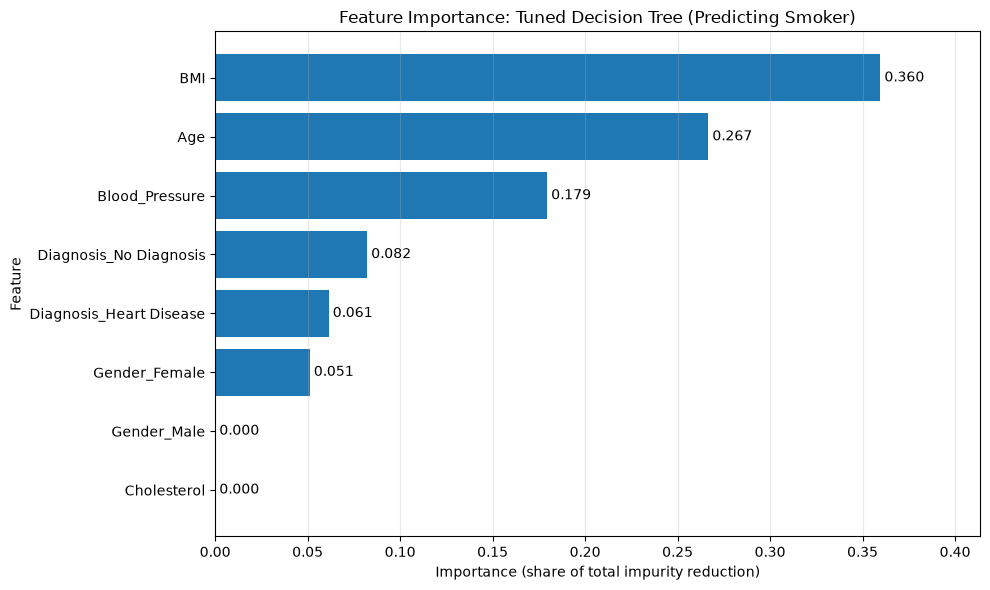

                Feature  Importance
                    BMI       0.360
                    Age       0.267
         Blood_Pressure       0.179
 Diagnosis_No Diagnosis       0.082
Diagnosis_Heart Disease       0.061
          Gender_Female       0.051
            Cholesterol       0.000
            Gender_Male       0.000


In [85]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance 

import matplotlib.pyplot as plt

best_tree = grid.best_estimator_

# Built-in (impurity-based) importance from the tuned tree
importance = (
    pd.DataFrame({"Feature": X_train.columns, "Importance": best_tree.feature_importances_})
    .sort_values("Importance")
)
importance["Std"] = 0

# Color bars: used by the tree vs. never used
colors = ["#1f77b4" if v > 0 else "#c7c7c7" for v in importance["Importance"]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(importance["Feature"], importance["Importance"], color=colors)

# Label each bar with its value
ax.bar_label(bars, labels=[f"{v:.3f}" for v in importance["Importance"]], padding=3)

ax.set_title("Feature Importance: Tuned Decision Tree (Predicting Smoker)")
ax.set_xlabel("Importance (share of total impurity reduction)")
ax.set_ylabel("Feature")
ax.set_xlim(0, importance["Importance"].max() * 1.15 if importance["Importance"].max() > 0 else 1)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print(importance.drop(columns="Std").sort_values("Importance", ascending=False).round(3).to_string(index=False))